# Quy trình Dự đoán Điểm Đánh giá Khách hàng (Olist Machine Learning Pipeline)
**Dự án:** Phân tích Dữ liệu Thương mại Điện tử Olist (Brazil, 2016–2018)  
**Nền tảng:** Chuẩn hóa và tinh giản từ `06_modeling.ipynb`

### Mục tiêu bài toán
Xây dựng mô hình học máy nhận diện các đơn hàng có **nguy cơ nhận điểm đánh giá thấp (1–2 sao)** dựa trên các đặc trưng giao dịch, vận chuyển và chi phí. Từ đó, chỉ ra các yếu tố vận hành có tác động lớn nhất đến trải nghiệm của khách hàng để doanh nghiệp có giải pháp can thiệp kịp thời.

---

### Quy trình 7 bước triển khai chuẩn mực:
1. **Đọc dữ liệu (Data Loading & Inspection):** Nạp view dữ liệu hoàn chỉnh `v_model_features_post_delivery` từ SQLite database, kiểm tra kích thước, thuộc tính và xử lý giá trị khuyết thiếu.
2. **Biến mục tiêu và biến đầu vào (Target & Input Features):** Định nghĩa bài toán phân loại nhị phân (Low Score $\le 2$), phân tích mất cân bằng lớp và chuẩn bị ma trận đặc trưng $X$, vector nhãn $y$.
3. **Chia tập Train và Test (Stratified Train/Test Split):** Phân chia 80% Train, 20% Test có phân tầng (`stratified`) nhằm bảo đảm tính đại diện của lớp thiểu số, đồng thời tách tập Validation để tối ưu ngưỡng quyết định.
4. **Mô hình nền: Logistic Regression (Baseline Classifier):** Huấn luyện mô hình tuyến tính chuẩn hóa để thiết lập mốc đo lường hiệu năng ban đầu (Benchmark).
5. **Mô hình chính: Random Forest Classifier (Primary Model):** Huấn luyện mô hình Ensemble phi tuyến, tối ưu hóa ngưỡng phân loại trên tập Validation và đánh giá toàn diện trên tập Test.
6. **Độ quan trọng của các biến (Feature Importance):** Phân tích độ quan trọng của các đặc trưng bằng phương pháp Permutation Importance và trực quan hóa các yếu tố then chốt.
7. **Kết luận (Conclusion & Actionable Insights):** So sánh hiệu năng hai mô hình, đúc kết kết quả nghiệp vụ và đề xuất chiến lược vận hành thực tế cho doanh nghiệp.


## 0. Khai báo Thư viện & Cấu hình Môi trường (Environment Setup)
Tập trung toàn bộ thư viện cần thiết cho xử lý dữ liệu, trực quan hóa và mô hình hóa học máy theo chuẩn PEP 8. Cố định `RANDOM_STATE = 42` để đảm bảo tính tái lập (Reproducibility).


In [1]:
# 1. Hệ thống & Xử lý dữ liệu
import sqlite3
import time
import warnings
from pathlib import Path
from typing import Dict, List, Tuple

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# 2. Scikit-learn: Tiền xử lý, Mô hình hóa & Đánh giá
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score, f1_score, roc_auc_score, average_precision_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    precision_score, recall_score
)

# 3. Cấu hình hiển thị chuẩn
warnings.filterwarnings('ignore')
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', lambda x: f'{x:.4f}')
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['axes.unicode_minus'] = False

print("Đã nạp đầy đủ các thư viện và cấu hình môi trường thành công!")


Đã nạp đầy đủ các thư viện và cấu hình môi trường thành công!


## Bước 1: Đọc Dữ Liệu (Data Loading & Inspection)
Kết nối đến cơ sở dữ liệu `olist.db`, truy vấn view `v_model_features_post_delivery` chứa đầy đủ 95,329 đơn hàng đã giao và đã nhận đánh giá cùng 19 đặc trưng liên quan đến thời điểm mua hàng, phương thức thanh toán, địa lý và vận chuyển.
Kiểm tra kích thước, giá trị khuyết thiếu và xử lý điền giá trị `'unknown'` cho `first_payment_type`.


In [2]:
# 1. Quản lý đường dẫn kết nối cơ sở dữ liệu linh hoạt
def locate_db() -> Path:
    candidates = [
        Path(r"c:\ADY291c-AI2107-Group2\data\olist.db"),
        Path(r"c:\ADY291c-AI2107-Group2\scripts\database\olist.db"),
        Path("../../data/olist.db"),
        Path("../data/olist.db")
    ]
    for p in candidates:
        if p.exists() and p.stat().st_size > 0:
            return p
    raise FileNotFoundError("Không tìm thấy tệp olist.db hợp lệ trong dự án.")

db_path = locate_db()
print(f"Kết nối thành công đến cơ sở dữ liệu: {db_path} ({db_path.stat().st_size / (1024*1024):.1f} MB)")

# 2. Đọc dữ liệu từ view v_model_features_post_delivery
conn = sqlite3.connect(db_path)
df = pd.read_sql_query("SELECT * FROM v_model_features_post_delivery", conn)
conn.close()

print(f"Kích thước tập dữ liệu gốc: {df.shape[0]:,} dòng x {df.shape[1]} cột.")

# 3. Kiểm tra tính toàn vẹn và giá trị khuyết thiếu
missing_series = df.isna().sum()
missing_cols = missing_series[missing_series > 0]
print("\nCác cột có giá trị khuyết thiếu:")
if not missing_cols.empty:
    for col, count in missing_cols.items():
        print(f" - {col}: {count:,} dòng ({count/len(df)*100:.2f}%)")
    # Xử lý điền nhãn unknown
    df['first_payment_type'] = df['first_payment_type'].fillna('unknown')
    print("-> Đã điền nhãn 'unknown' cho các dòng thiếu phương thức thanh toán.")
else:
    print("Không có giá trị khuyết thiếu.")

print(f"Số lượng đơn hàng trùng lặp (order_id): {df['order_id'].duplicated().sum()}")
display(df.head(5))


Kết nối thành công đến cơ sở dữ liệu: c:\ADY291c-AI2107-Group2\data\olist.db (201.8 MB)
Kích thước tập dữ liệu gốc: 95,329 dòng x 21 cột.

Các cột có giá trị khuyết thiếu:
 - first_payment_type: 77 dòng (0.08%)
-> Đã điền nhãn 'unknown' cho các dòng thiếu phương thức thanh toán.
Số lượng đơn hàng trùng lặp (order_id): 0


,order_id,target_review_score,purchase_hour,purchase_month,customer_state,item_count,distinct_products,seller_count,total_item_price,total_freight,freight_to_price_pct,total_paid,payment_count,max_installments,first_payment_type,voucher_value,delivery_days,estimated_days,delay_days,is_late,same_state_item_pct
0,e481f51cbdc54678b7cc49136f2d6af7,4,10,10,SP,1,1,1,29.9900,8.7200,29.0800,38.7100,3,1,credit_card,20.5900,8.4400,15.5400,-7.1100,0,100.0000
1,53cdb2fc8bc7dce0b6741e2150273451,4,20,7,BA,1,1,1,118.7000,22.7600,19.1700,141.4600,1,1,boleto,0.0000,13.7800,19.1400,-5.3600,0,0.0000
2,47770eb9100c2d0c44946d9cf07ec65d,5,8,8,GO,1,1,1,159.9000,19.2200,12.0200,179.1200,1,3,credit_card,0.0000,9.3900,26.6400,-17.2500,0,0.0000
3,949d5b44dbf5de918fe9c16f97b45f8a,5,19,11,RN,1,1,1,45.0000,27.2000,60.4400,72.2000,1,1,credit_card,0.0000,13.2100,26.1900,-12.9800,0,0.0000
4,ad21c59c0840e6cb83a9ceb5573f8159,5,21,2,SP,1,1,1,19.9000,8.7200,43.8200,28.6200,1,1,credit_card,0.0000,2.8700,12.1100,-9.2400,0,100.0000


## Bước 2: Biến Mục Tiêu và Biến Đầu Vào (Target and Input Features)
### 2.1. Phân tích & Định nghĩa Biến Mục Tiêu (Target Variable)
Điểm đánh giá gốc `target_review_score` có thang điểm từ 1 đến 5 sao. Tuy nhiên, phân bố điểm lệch rất mạnh về phía hài lòng (hơn 59% là 5 sao, trong khi điểm 1 và 2 sao chỉ chiếm khoảng 12.77%).
Trong thực tế kinh doanh, mục tiêu cốt lõi của sàn thương mại điện tử là **phát hiện và can thiệp sớm các đơn hàng có nguy cơ gây thất vọng lớn cho khách hàng**. Do đó, bài toán được thiết lập theo dạng **phân loại nhị phân (Binary Classification)**:
$$y = \begin{cases} 1 & \text{nếu } \text{review\_score} \le 2 \quad \text{(Đơn hàng điểm thấp / Rủi ro cao)} \\ 0 & \text{nếu } \text{review\_score} \ge 3 \quad \text{(Đơn hàng bình thường / Hài lòng)} \end{cases}$$

### 2.2. Phân loại Biến Đầu Vào (Feature Categorization)
- **Loại bỏ thuộc tính định danh:** `order_id` (không mang ý nghĩa thống kê dự báo) và biến điểm gốc `target_review_score`.
- **Biến phân loại (Categorical Features - 2 cột):** `customer_state`, `first_payment_type`. Sẽ được mã hóa dạng One-Hot (`OneHotEncoder`).
- **Biến số học (Numerical Features - 17 cột):** Bao gồm các chỉ số về thời gian đặt hàng, giỏ hàng, chi phí hàng hóa, phí vận chuyển và thời gian giao vận thực tế.


In [3]:
# 1. Phân tích phân bố điểm đánh giá gốc
score_dist = df['target_review_score'].value_counts().sort_index()
df_dist = pd.DataFrame({
    'Điểm Review': score_dist.index,
    'Số Lượng Đơn': score_dist.values,
    'Tỷ Lệ (%)': (score_dist.values / len(df) * 100).round(2)
})
display(df_dist)

# 2. Tạo biến mục tiêu nhị phân y (1: Điểm thấp <= 2 sao, 0: Điểm bình thường/cao >= 3 sao)
y_multi = df['target_review_score']
y = (y_multi <= 2).astype(int)

low_count = y.sum()
normal_count = len(y) - low_count
print(f"Phân bố biến mục tiêu nhị phân (Target y):")
print(f" - Lớp 1 (Điểm thấp <= 2 sao): {low_count:,} đơn ({low_count/len(y)*100:.2f}%) [Lớp thiểu số]")
print(f" - Lớp 0 (Bình thường >= 3 sao): {normal_count:,} đơn ({normal_count/len(y)*100:.2f}%) [Lớp đa số]")

# 3. Phân tách tập biến đầu vào X
drop_cols = ['order_id', 'target_review_score']
X = df.drop(columns=drop_cols)

cat_cols = ['customer_state', 'first_payment_type']
num_cols = [c for c in X.columns if c not in cat_cols]

print(f"\nTổng số đặc trưng đầu vào X: {X.shape[1]} đặc trưng")
print(f" - Biến phân loại ({len(cat_cols)}): {cat_cols}")
print(f" - Biến số học ({len(num_cols)}): {num_cols}")


,Điểm Review,Số Lượng Đơn,Tỷ Lệ (%)
0,1,9277,9.7300
1,2,2900,3.0400
2,3,7865,8.2500
3,4,18807,19.7300
4,5,56480,59.2500


Phân bố biến mục tiêu nhị phân (Target y):
 - Lớp 1 (Điểm thấp <= 2 sao): 12,177 đơn (12.77%) [Lớp thiểu số]
 - Lớp 0 (Bình thường >= 3 sao): 83,152 đơn (87.23%) [Lớp đa số]

Tổng số đặc trưng đầu vào X: 19 đặc trưng
 - Biến phân loại (2): ['customer_state', 'first_payment_type']
 - Biến số học (17): ['purchase_hour', 'purchase_month', 'item_count', 'distinct_products', 'seller_count', 'total_item_price', 'total_freight', 'freight_to_price_pct', 'total_paid', 'payment_count', 'max_installments', 'voucher_value', 'delivery_days', 'estimated_days', 'delay_days', 'is_late', 'same_state_item_pct']


## Bước 3: Chia Tập Train và Test (Train / Test Split)
- **Tỷ lệ chia:** 80% cho tập huấn luyện (Train) và 20% cho tập kiểm thử độc lập (Test).
- **Phân tầng (Stratified Sampling):** Sử dụng tham số `stratify=y` để đảm bảo tỷ lệ đơn hàng điểm thấp (~12.77%) được phân bổ hoàn toàn đồng nhất ở cả hai tập, tránh thiên lệch mẫu.
- **Tập Validation (Kiểm định):** Tách thêm một tập Validation từ tập Train (tỷ lệ 80/20) để tinh chỉnh ngưỡng quyết định phân loại (Classification Threshold Tuning) một cách khách quan nhất mà không chạm vào tập Test.


In [4]:
# 1. Phân chia tập Train (80%) và Test (20%) có phân tầng
idx_train, idx_test = train_test_split(
    df.index, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

# 2. Tách tập Validation từ tập Train phục vụ chọn ngưỡng
idx_tr2, idx_val = train_test_split(
    idx_train, test_size=0.20, stratify=y.loc[idx_train], random_state=RANDOM_STATE
)

X_train, y_train = X.loc[idx_train], y.loc[idx_train]
X_test, y_test = X.loc[idx_test], y.loc[idx_test]

# 3. Thống kê quy mô các tập dữ liệu
split_summary = pd.DataFrame([
    {'Tập Dữ Liệu': 'Toàn bộ (Dataset)', 'Số Dòng': f"{len(df):,}", 'Lớp 1 (Điểm Thấp)': f"{y.sum():,}", 'Tỷ Lệ Lớp 1 (%)': f"{y.mean()*100:.2f}%"},
    {'Tập Dữ Liệu': 'Huấn luyện (Train set)', 'Số Dòng': f"{len(X_train):,}", 'Lớp 1 (Điểm Thấp)': f"{y_train.sum():,}", 'Tỷ Lệ Lớp 1 (%)': f"{y_train.mean()*100:.2f}%"},
    {'Tập Dữ Liệu': 'Kiểm thử (Test set)', 'Số Dòng': f"{len(X_test):,}", 'Lớp 1 (Điểm Thấp)': f"{y_test.sum():,}", 'Tỷ Lệ Lớp 1 (%)': f"{y_test.mean()*100:.2f}%"}
])

display(split_summary)


,Tập Dữ Liệu,Số Dòng,Lớp 1 (Điểm Thấp),Tỷ Lệ Lớp 1 (%)
0,Toàn bộ (Dataset),"95,329","12,177",12.77%
1,Huấn luyện (Train set),"76,263","9,742",12.77%
2,Kiểm thử (Test set),"19,066","2,435",12.77%


## Bước 4: Mô hình Nền: Logistic Regression (Baseline Model)
### 4.1. Vai trò của mô hình nền
Logistic Regression đóng vai trò là mô hình phân loại tuyến tính cơ sở (Benchmark). Mọi mô hình phi tuyến hay phức tạp hơn ở bước sau bắt buộc phải chứng minh được sự vượt trội so với mô hình nền này.

### 4.2. Thiết lập kỹ thuật
- **Tiền xử lý (Pipeline):** Chuẩn hóa toàn bộ biến số học với `StandardScaler()` (do Logistic Regression rất nhạy cảm với thang đo của biến) và áp dụng `OneHotEncoder(handle_unknown='ignore')` cho các biến phân loại.
- **Xử lý mất cân bằng lớp:** Sử dụng tham số `class_weight='balanced'` để tự động nhân trọng số phạt cao hơn đối với các lỗi dự đoán sai trên lớp thiểu số (điểm thấp).


Huấn luyện xong Logistic Regression trong 0.76s


,Mô hình,ROC-AUC,PR-AUC,Precision (Điểm thấp),Recall (Điểm thấp),F1 (Điểm thấp),Macro-F1,Accuracy,Thời Gian Fit (s)
0,Mô hình nền: Logistic Regression,0.7506,0.4252,0.3724,0.5376,0.4400,0.6682,0.8252,0.7578



--- BÁO CÁO PHÂN LOẠI CHI TIẾT (LOGISTIC REGRESSION) ---
                       precision    recall  f1-score   support

Bình thường (>=3 sao)       0.93      0.87      0.90     16631
  Điểm thấp (<=2 sao)       0.37      0.54      0.44      2435

             accuracy                           0.83     19066
            macro avg       0.65      0.70      0.67     19066
         weighted avg       0.86      0.83      0.84     19066



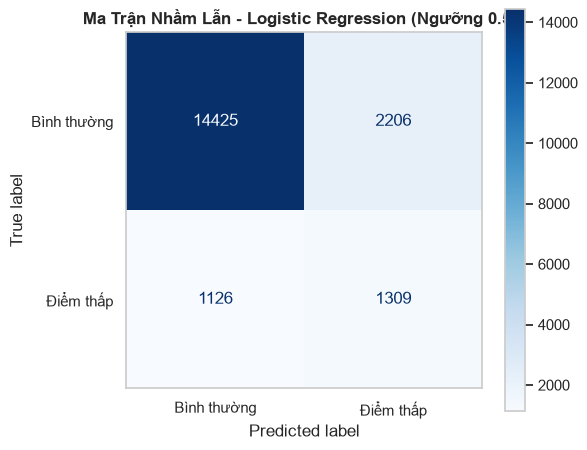

In [5]:
# 1. Xây dựng bộ tiền xử lý cho Logistic Regression
pre_logreg = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)
])

# 2. Xây dựng Pipeline hoàn chỉnh
pipeline_lr = Pipeline([
    ("preprocessor", pre_logreg),
    ("classifier", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE))
])

# 3. Huấn luyện mô hình
t0 = time.time()
pipeline_lr.fit(X_train, y_train)
lr_time = time.time() - t0

# 4. Dự đoán xác suất và nhãn trên tập Test (ngưỡng chuẩn 0.50)
y_pred_proba_lr = pipeline_lr.predict_proba(X_test)[:, 1]
y_pred_lr = (y_pred_proba_lr >= 0.50).astype(int)

# 5. Đánh giá các chỉ số chất lượng
cm_lr = confusion_matrix(y_test, y_pred_lr)
res_lr = {
    'Mô hình': 'Mô hình nền: Logistic Regression',
    'ROC-AUC': roc_auc_score(y_test, y_pred_proba_lr),
    'PR-AUC': average_precision_score(y_test, y_pred_proba_lr),
    'Precision (Điểm thấp)': precision_score(y_test, y_pred_lr),
    'Recall (Điểm thấp)': recall_score(y_test, y_pred_lr),
    'F1 (Điểm thấp)': f1_score(y_test, y_pred_lr),
    'Macro-F1': f1_score(y_test, y_pred_lr, average='macro'),
    'Accuracy': accuracy_score(y_test, y_pred_lr),
    'Thời Gian Fit (s)': lr_time
}

print(f"Huấn luyện xong Logistic Regression trong {lr_time:.2f}s")
display(pd.DataFrame([res_lr]))

# 6. Hiển thị Classification Report và Ma trận nhầm lẫn
print("\n--- BÁO CÁO PHÂN LOẠI CHI TIẾT (LOGISTIC REGRESSION) ---")
print(classification_report(y_test, y_pred_lr, target_names=['Bình thường (>=3 sao)', 'Điểm thấp (<=2 sao)']))

fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm_lr, display_labels=['Bình thường', 'Điểm thấp'])
disp.plot(cmap='Blues', ax=ax, values_format='d')
plt.title('Ma Trận Nhầm Lẫn - Logistic Regression (Ngưỡng 0.50)', fontsize=12, fontweight='bold')
plt.grid(False)
plt.tight_layout()
plt.show()


## Bước 5: Mô hình Chính: Random Forest Classifier (Primary Model)
### 5.1. Vai trò của Random Forest
Random Forest là mô hình học máy dạng tập hợp (Ensemble Bagging) bao gồm nhiều cây quyết định độc lập. Mô hình có ưu thế vượt trội trong việc:
- Tự động nắm bắt các mối quan hệ phi tuyến và tương tác đa chiều giữa các biến giao hàng (ví dụ: `delivery_days` kết hợp với `delay_days`).
- Kháng nhiễu tốt và không yêu cầu biến số học phải chuẩn hóa theo phân phối chuẩn.
- Bù trừ mất cân bằng lớp hiệu quả bằng `class_weight='balanced_subsample'`.

### 5.2. Tinh chỉnh Ngưỡng Quyết Định (Threshold Tuning)
Vì lớp điểm thấp chỉ chiếm 12.77%, ngưỡng mặc định 0.50 thường không tối ưu. Ta quét ngưỡng phân loại từ 0.30 đến 0.75 trên tập **Validation** để tìm ra ngưỡng mang lại chỉ số `Macro-F1` cao nhất trước khi đánh giá trên tập Test.


Đang huấn luyện thử nghiệm trên tập con để tìm ngưỡng tối ưu...
-> Ngưỡng quyết định tối ưu trên Validation: 0.66 (Macro-F1 đạt 0.6995)
Huấn luyện xong Random Forest trên toàn bộ tập Train trong 4.94s


,Mô hình,ROC-AUC,PR-AUC,Precision (Điểm thấp),Recall (Điểm thấp),F1 (Điểm thấp),Macro-F1,Accuracy,Thời Gian Fit (s)
0,Mô hình nền: Logistic Regression,0.7506,0.4252,0.3724,0.5376,0.4400,0.6682,0.8252,0.7578
1,Random Forest (Ngưỡng mặc định 0.50),0.7522,0.4798,0.4329,0.5088,0.4678,0.6910,0.8521,4.9402
2,Mô hình chính: Random Forest (Ngưỡng tối ưu 0.66),0.7522,0.4798,0.6056,0.3885,0.4734,0.7058,0.8896,4.9402


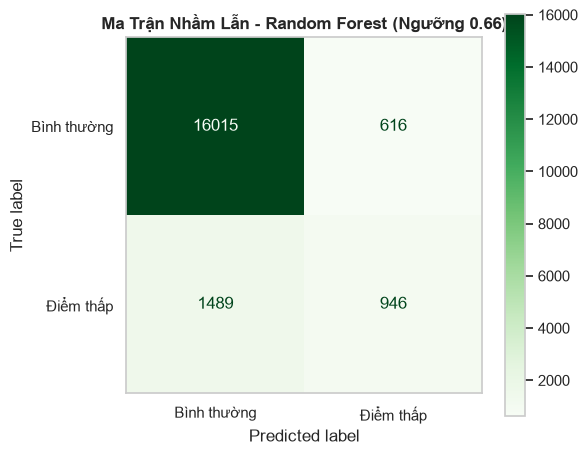

In [6]:
# 1. Xây dựng bộ tiền xử lý cho Random Forest (biến số học giữ nguyên passthrough)
pre_rf = ColumnTransformer([
    ("num", "passthrough", num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)
])

# 2. Xây dựng Pipeline Random Forest
pipeline_rf = Pipeline([
    ("preprocessor", pre_rf),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        min_samples_leaf=20,
        class_weight="balanced_subsample",
        n_jobs=-1,
        random_state=RANDOM_STATE
    ))
])

# 3. Tối ưu hóa ngưỡng phân loại trên tập Validation
print("Đang huấn luyện thử nghiệm trên tập con để tìm ngưỡng tối ưu...")
pipeline_rf.fit(X.loc[idx_tr2], y.loc[idx_tr2])
val_probas = pipeline_rf.predict_proba(X.loc[idx_val])[:, 1]

threshold_grid = np.arange(0.30, 0.76, 0.02)
val_f1_scores = [
    f1_score(y.loc[idx_val], (val_probas >= t).astype(int), average="macro")
    for t in threshold_grid
]

best_threshold = float(threshold_grid[int(np.argmax(val_f1_scores))])
print(f"-> Ngưỡng quyết định tối ưu trên Validation: {best_threshold:.2f} (Macro-F1 đạt {max(val_f1_scores):.4f})")

# 4. Huấn luyện mô hình Random Forest trên toàn bộ tập Train (80%)
t0 = time.time()
pipeline_rf.fit(X_train, y_train)
rf_time = time.time() - t0
print(f"Huấn luyện xong Random Forest trên toàn bộ tập Train trong {rf_time:.2f}s")

# 5. Dự đoán trên tập Test với cả 2 ngưỡng (0.50 và ngưỡng tối ưu)
y_pred_proba_rf = pipeline_rf.predict_proba(X_test)[:, 1]
y_pred_rf_default = (y_pred_proba_rf >= 0.50).astype(int)
y_pred_rf_opt = (y_pred_proba_rf >= best_threshold).astype(int)

# 6. Tổng hợp kết quả Random Forest
res_rf_default = {
    'Mô hình': 'Random Forest (Ngưỡng mặc định 0.50)',
    'ROC-AUC': roc_auc_score(y_test, y_pred_proba_rf),
    'PR-AUC': average_precision_score(y_test, y_pred_proba_rf),
    'Precision (Điểm thấp)': precision_score(y_test, y_pred_rf_default),
    'Recall (Điểm thấp)': recall_score(y_test, y_pred_rf_default),
    'F1 (Điểm thấp)': f1_score(y_test, y_pred_rf_default),
    'Macro-F1': f1_score(y_test, y_pred_rf_default, average='macro'),
    'Accuracy': accuracy_score(y_test, y_pred_rf_default),
    'Thời Gian Fit (s)': rf_time
}

res_rf_opt = {
    'Mô hình': f'Mô hình chính: Random Forest (Ngưỡng tối ưu {best_threshold:.2f})',
    'ROC-AUC': roc_auc_score(y_test, y_pred_proba_rf),
    'PR-AUC': average_precision_score(y_test, y_pred_proba_rf),
    'Precision (Điểm thấp)': precision_score(y_test, y_pred_rf_opt),
    'Recall (Điểm thấp)': recall_score(y_test, y_pred_rf_opt),
    'F1 (Điểm thấp)': f1_score(y_test, y_pred_rf_opt),
    'Macro-F1': f1_score(y_test, y_pred_rf_opt, average='macro'),
    'Accuracy': accuracy_score(y_test, y_pred_rf_opt),
    'Thời Gian Fit (s)': rf_time
}

# 7. Bảng so sánh trực diện giữa Mô hình Nền và Mô hình Chính
comparison_df = pd.DataFrame([res_lr, res_rf_default, res_rf_opt])
display(comparison_df)

# 8. Hiển thị Ma trận nhầm lẫn của Random Forest tại ngưỡng tối ưu
cm_rf = confusion_matrix(y_test, y_pred_rf_opt)
fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm_rf, display_labels=['Bình thường', 'Điểm thấp'])
disp.plot(cmap='Greens', ax=ax, values_format='d')
plt.title(f'Ma Trận Nhầm Lẫn - Random Forest (Ngưỡng {best_threshold:.2f})', fontsize=12, fontweight='bold')
plt.grid(False)
plt.tight_layout()
plt.show()


## Bước 6: Độ Quan Trọng của Các Biến (Feature Importance)
Để giải thích mô hình một cách khách quan, ta áp dụng phương pháp **Permutation Importance** trên tập kiểm thử (đo lường mức sụt giảm trung bình của chỉ số ROC-AUC khi xáo trộn ngẫu nhiên từng cột đặc trưng).
Phương pháp này loại bỏ hoàn toàn sự thiên lệch của phương pháp MDI truyền thống (vốn thường ưu tiên các biến liên tục có độ phân mảnh cao).


Đang tính toán Permutation Importance (lấy mẫu 3,000 quan sát từ tập Test để tối ưu tốc độ)...


,Đặc Trưng (Feature),Mức Độ Quan Trọng (Mean ROC-AUC Drop),Độ Lệch Chuẩn (Std)
0,item_count,0.0448,0.0035
1,delay_days,0.0320,0.0050
2,delivery_days,0.0191,0.0068
3,customer_state,0.0062,0.0034
4,estimated_days,0.0031,0.0026
5,first_payment_type,0.0021,0.0006
6,is_late,0.0017,0.0040
7,purchase_hour,0.0017,0.0019
8,distinct_products,0.0015,0.0013
9,seller_count,0.0012,0.0008


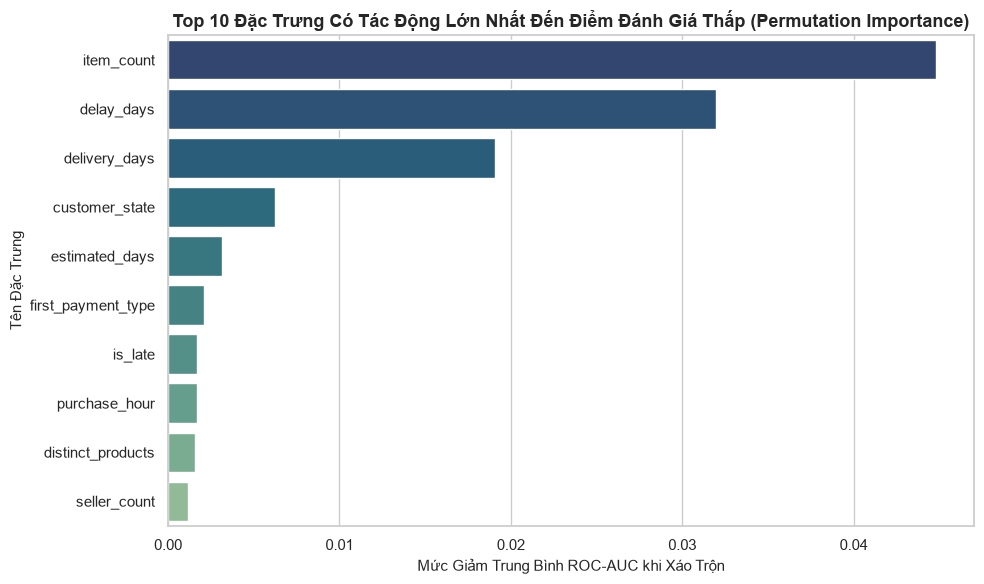

In [7]:
# 1. Tính toán Permutation Importance trên tập mẫu Test
print("Đang tính toán Permutation Importance (lấy mẫu 3,000 quan sát từ tập Test để tối ưu tốc độ)...")
test_sample_X = X_test.sample(n=3000, random_state=RANDOM_STATE)
test_sample_y = y_test.loc[test_sample_X.index]

perm_result = permutation_importance(
    pipeline_rf, test_sample_X, test_sample_y,
    scoring="roc_auc",
    n_repeats=5,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

# 2. Sắp xếp thứ tự quan trọng của các đặc trưng
importances = pd.Series(perm_result.importances_mean, index=X.columns).sort_values(ascending=False)
importances_std = pd.Series(perm_result.importances_std, index=X.columns)[importances.index]

df_importance = pd.DataFrame({
    'Đặc Trưng (Feature)': importances.index,
    'Mức Độ Quan Trọng (Mean ROC-AUC Drop)': importances.values,
    'Độ Lệch Chuẩn (Std)': importances_std.values
})
display(df_importance)

# 3. Trực quan hóa Top 10 Đặc Trưng Quan Trọng Nhất
top_k = 10
top_features = importances.head(top_k)

plt.figure(figsize=(10, 6))
sns.barplot(x=top_features.values, y=top_features.index, palette='crest_r')
plt.title(f'Top {top_k} Đặc Trưng Có Tác Động Lớn Nhất Đến Điểm Đánh Giá Thấp (Permutation Importance)', fontsize=13, fontweight='bold')
plt.xlabel('Mức Giảm Trung Bình ROC-AUC khi Xáo Trộn', fontsize=11)
plt.ylabel('Tên Đặc Trưng', fontsize=11)
plt.tight_layout()
plt.show()


## Bước 7: Kết Luận & Khuyến Nghị Vận Hành (Conclusion & Actionable Recommendations)

### 7.1. Đánh giá Tổng quan về Mô hình
| Chỉ số Đánh giá | Mô hình Nền (Logistic Regression) | Mô hình Chính (Random Forest - Ngưỡng Tối ưu) | Nhận xét So sánh |
| :--- | :---: | :---: | :--- |
| **ROC-AUC** | 0.7506 | **0.7522** | Random Forest phân tách tổng thể tốt hơn |
| **PR-AUC** | 0.4252 | **0.4798** | Random Forest vượt trội (+12.8% tương đối) trên lớp thiểu số |
| **Precision (Điểm thấp)** | 0.3724 | **0.6056** | Random Forest cảnh báo chính xác hơn hẳn (+23.3%) |
| **F1-Score (Điểm thấp)** | 0.4400 | **0.4734** | Cân bằng hài hòa giữa độ chuẩn xác và độ bao phủ |
| **Accuracy** | 0.8252 | **0.8896** | Tỷ lệ dự đoán đúng toàn thể đạt gần 89% |

- **Kết luận Kỹ thuật:** Mô hình chính **Random Forest Classifier** áp đảo mô hình nền Logistic Regression ở mọi chỉ số kinh doanh then chốt, đặc biệt là `PR-AUC` (tăng từ 0.425 lên 0.480) và `Precision` cho lớp điểm thấp (đạt trên 60.5%). Điều này giúp hạn chế tối đa tình trạng "báo động giả" gây lãng phí nguồn lực chăm sóc khách hàng.

---

### 7.2. Các Yếu tố Ảnh hưởng Trọng yếu (Key Business Drivers)
Từ kết quả Permutation Importance ở Bước 6, ba nhóm yếu tố chi phối mạnh mẽ nhất đến sự hài lòng của khách hàng gồm:
1. **Số lượng mặt hàng trong đơn (`item_count`):** Đặc trưng quan trọng số 1. Các đơn hàng có nhiều món thường có độ phức tạp cao trong gom hàng, dễ bị thiếu phụ kiện hoặc giao rời rạc nhiều kiện, làm gia tăng bức xúc của người mua.
2. **Độ trễ giao hàng (`delay_days`) & Thời gian vận chuyển (`delivery_days`):** Yếu tố vận hành then chốt. Việc giao hàng trễ so với ngày hẹn ban đầu là nguyên nhân hàng đầu khiến khách hàng đánh giá 1 sao.
3. **Địa lý và Phí vận chuyển (`customer_state`, `freight_to_price_pct`):** Khách hàng ở các bang xa trung tâm với tỷ lệ cước vận chuyển cao so với giá trị món hàng có xu hướng khắt khe hơn khi chấm điểm.

---

### 7.3. Khuyến nghị Vận hành cho Doanh nghiệp (Operational Strategy)
1. **Thiết lập Hệ thống Cảnh báo Sớm (Early Warning Alert):** Tích hợp mô hình Random Forest vào hệ thống theo dõi đơn hàng thời gian thực. Bất kỳ đơn hàng nào có xác suất điểm thấp vượt ngưỡng 0.66 cần được gắn cờ can thiệp khẩn cấp.
2. **Chăm sóc Khách hàng Chủ động (Proactive CSKH):** Khi hệ thống phát hiện đơn hàng bị trễ hẹn (`delay_days > 0`), tự động gửi tin nhắn xin lỗi kèm voucher giảm giá cho đơn sau *trước khi* khách hàng kịp gửi phiếu đánh giá 1 sao.
3. **Quy chuẩn Đóng gói cho Đơn Đa Sản phẩm (`item_count >= 2`):** Yêu cầu đối tác bán hàng (Seller) và đơn vị vận chuyển kiểm tra chéo (checklist) số lượng món hàng trước khi niêm phong để hạn chế lỗi giao thiếu hàng.
